## **Project 2 Multi-label Emotion Classification**

### **Load Dataset**

In [ ]:
!pip install -q datasets transformers accelerate scikit-learn seaborn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from itertools import combinations
from sklearn.model_selection import train_test_split
from sklearn.metrics import (precision_score, recall_score, f1_score, hamming_loss, classification_report)
from datasets import load_dataset

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModel, AutoConfig)

from itertools import combinations

import random
import os

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
CUDA available: True


In [ ]:
dataset = load_dataset("AiLab-IMCS-UL/go_emotions-en", "simplified_ekman")
print(dataset)

README.md:   0%|          | 0.00/3.61k [00:00<?, ?B/s]

simplified_ekman/train-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B / 2.71MB            

simplified_ekman/train-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

simplified_ekman/validation-00000-of-000(…): reconstructing file:   0%|          |  0.00B /  345kB            

simplified_ekman/validation-00000-of-000(…): downloading bytes:           |  0.00B            

...

simplified_ekman/test-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'labels_ekman', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'labels_ekman', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'labels_ekman', 'id'],
        num_rows: 5427
    })
})


In [ ]:
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

### **Dataset specification dan data validation**

In [ ]:
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (43410, 4)
Validation: (5426, 4)
Test: (5427, 4)


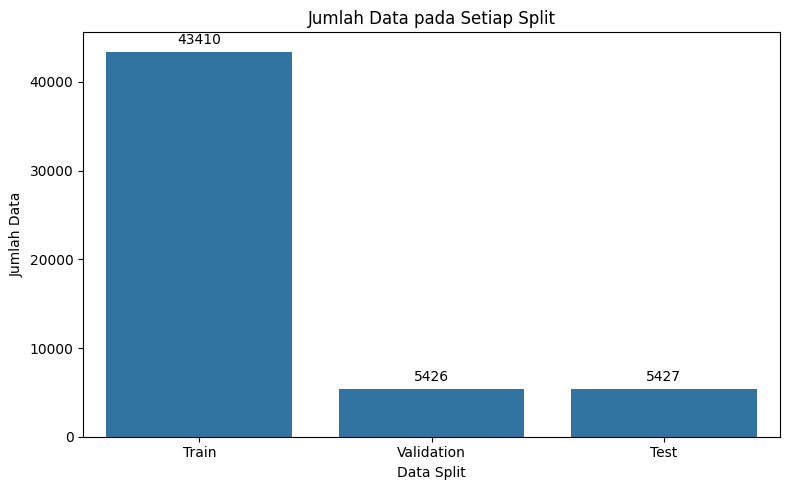

In [ ]:
# Diagram jumlah data per split
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Jumlah Data": [
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=split_summary,
    x="Dataset",
    y="Jumlah Data"
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.title("Jumlah Data pada Setiap Split")
plt.xlabel("Data Split")
plt.ylabel("Jumlah Data")
plt.tight_layout()
plt.show()

In [ ]:
print("Missing value TRAIN:")
print(train_df.isnull().sum())

print("\nMissing value VALIDATION:")
print(val_df.isnull().sum())

Missing value TRAIN:
text            0
labels          0
labels_ekman    0
id              0
dtype: int64

Missing value VALIDATION:
text            0
labels          0
labels_ekman    0
id              0
dtype: int64


In [ ]:
for name, df in [("Train", train_df), ("\nValidation", val_df)]:
    print(f"{name}")
    print("Duplicate ID   :", df["id"].duplicated().sum())
    print("Duplicate Text :", df["text"].duplicated().sum())

Train
Duplicate ID   : 0
Duplicate Text : 183

Validation
Duplicate ID   : 0
Duplicate Text : 3


In [ ]:
LABELS = [
    "anger",
    "disgust",
    "fear",
    "joy",
    "sadness",
    "surprise",
    "neutral"
]

LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}

print(LABEL2ID)

{'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'sadness': 4, 'surprise': 5, 'neutral': 6}


In [ ]:
VALID_LABEL_IDS = set(range(7))

def check_invalid_labels(df):
    invalid = []

    for idx, labels in enumerate(df["labels_ekman"]):
        for label in labels:
            if label not in VALID_LABEL_IDS:
                invalid.append((idx, label))

    return invalid

for name, df in [("Train", train_df), ("Validation", val_df)]:
    invalid = check_invalid_labels(df)

    print(name, "invalid labels:", len(invalid))

Train invalid labels: 0
Validation invalid labels: 0


In [ ]:
for name, df in [("Train", train_df), ("Validation", val_df)]:
    zero_label = (df["labels_ekman"].apply(len) == 0).sum()

    print(name, "data tanpa label:", zero_label)

Train data tanpa label: 0
Validation data tanpa label: 0


### **Exploratory Data Analysis (EDA)**

In [ ]:
# 1. Konversi labels_ekman (list ID) menjadi kolom multi-hot
# Contoh: [0, 3] akan menjadi 1 pada dua label yang sesuai dan 0 pada label lainnya.
def add_label_columns(df):
    df = df.copy()
    for label_id, label_name in enumerate(LABELS):
        df[label_name] = df["labels_ekman"].apply(
            lambda ids: int(label_id in ids)
        )
    df["num_labels"] = df[LABELS].sum(axis=1)
    return df

train_df = add_label_columns(train_df)
val_df = add_label_columns(val_df)
test_df = add_label_columns(test_df)

print("Contoh kolom hasil multi-hot encoding:")
display(train_df[["text", "labels_ekman"] + LABELS + ["num_labels"]].head())

print("\nJumlah label per split:")
for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{split_name}: {len(split_df):,} data")

Contoh kolom hasil multi-hot encoding:


,text,labels_ekman,anger,disgust,fear,joy,sadness,surprise,neutral,num_labels
0,My favourite food is anything I didn't have to...,[6],0,0,0,0,0,0,1,1
1,"Now if he does off himself, everyone will thin...",[6],0,0,0,0,0,0,1,1
2,WHY THE FUCK IS BAYLESS ISOING,[0],1,0,0,0,0,0,0,1
3,To make her feel threatened,[2],0,0,1,0,0,0,0,1
4,Dirty Southern Wankers,[0],1,0,0,0,0,0,0,1



Jumlah label per split:
Train: 43,410 data
Validation: 5,426 data
Test: 5,427 data


,label,jumlah,proporsi_data_%
0,joy,17410,40.11
1,neutral,14219,32.76
2,anger,5579,12.85
3,surprise,5367,12.36
4,sadness,3263,7.52
5,disgust,793,1.83
6,fear,726,1.67


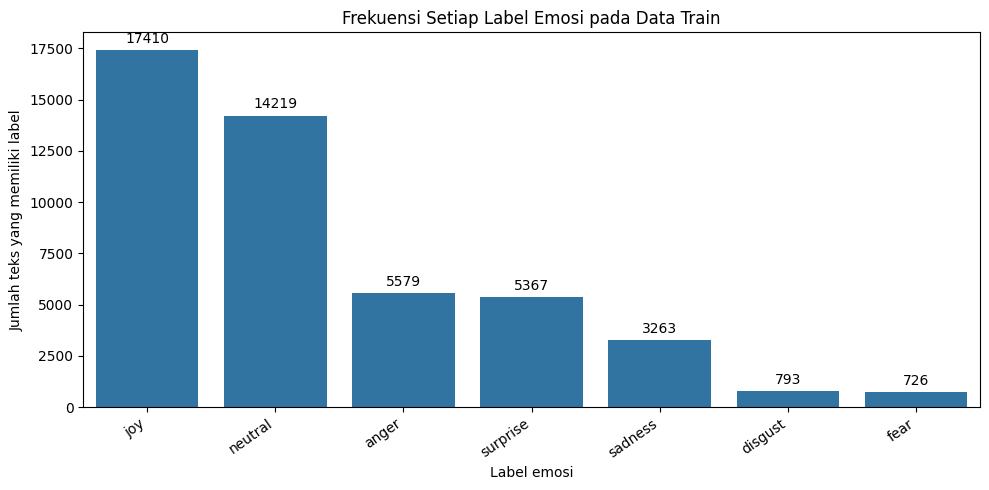

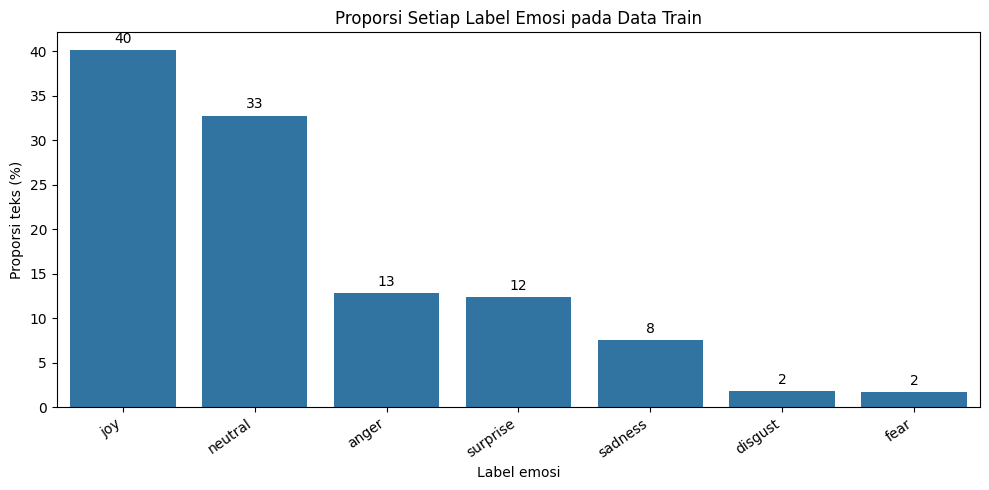

Label paling jarang: fear
Label paling sering: joy


In [ ]:
# 2. Frekuensi dan proporsi masing-masing label (data train)
label_frequency = train_df[LABELS].sum().sort_values(ascending=False)
label_proportion = train_df[LABELS].mean().mul(100)

label_summary = pd.DataFrame({
    "label": LABELS,
    "jumlah": [int(train_df[label].sum()) for label in LABELS],
    "proporsi_data_%": [train_df[label].mean() * 100 for label in LABELS]
}).sort_values("jumlah", ascending=False).reset_index(drop=True)

display(label_summary.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(data=label_summary, x="label", y="jumlah")
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.title("Frekuensi Setiap Label Emosi pada Data Train")
plt.xlabel("Label emosi")
plt.ylabel("Jumlah teks yang memiliki label")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=label_summary, x="label", y="proporsi_data_%")
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.title("Proporsi Setiap Label Emosi pada Data Train")
plt.xlabel("Label emosi")
plt.ylabel("Proporsi teks (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Label paling jarang:", label_summary.iloc[-1]["label"])
print("Label paling sering:", label_summary.iloc[0]["label"])

,kategori,jumlah,proporsi_%
0,Tanpa label,0,0.00
1,Single-label,39555,91.12
2,Multi-label,3855,8.88


/tmp/ipykernel_3049/3225691165.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=type_summary, x="kategori", y="jumlah", ax=axes[0], palette="viridis")


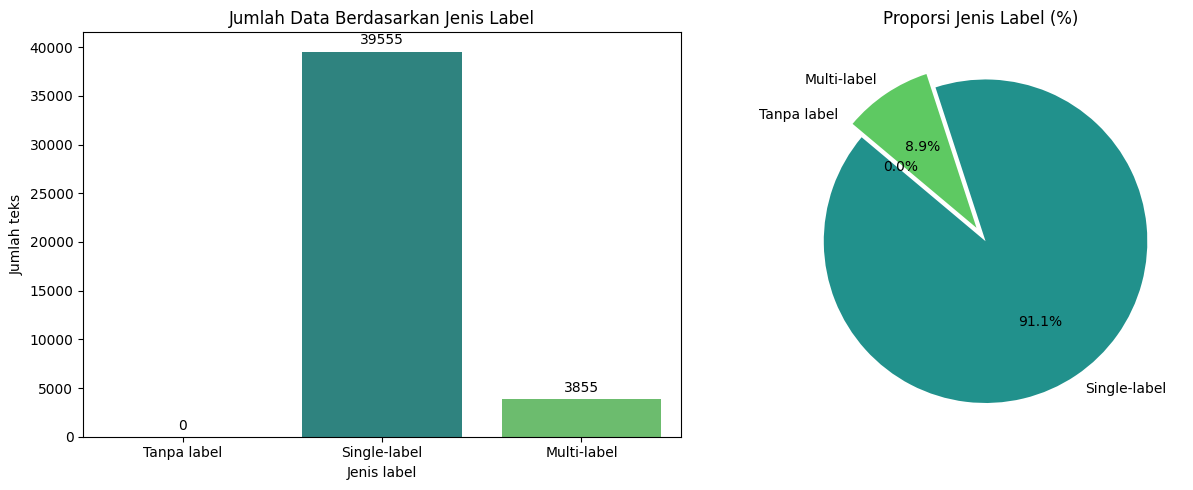

,jumlah_label,jumlah_teks
0,1,39555
1,2,3763
2,3,92


/tmp/ipykernel_3049/3225691165.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=label_count_distribution, x="jumlah_label", y="jumlah_teks", palette="Blues_d")


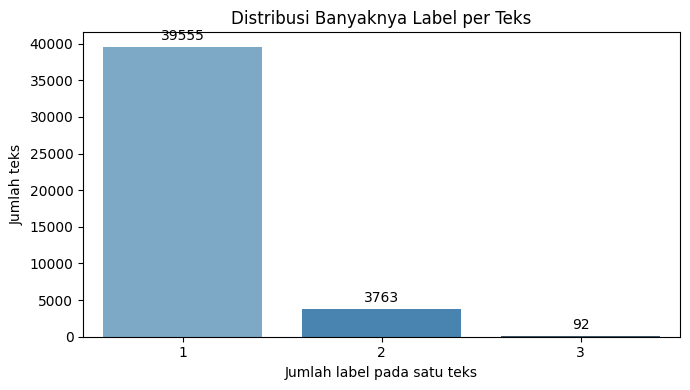

Label cardinality (train): 1.0909
Artinya, rata-rata satu teks memiliki sekitar 1.09 label.


In [ ]:
# 3. Distribusi single-label, multi-label, dan data tanpa label
# Single-label: tepat 1 label; multi-label: 2 label atau lebih.
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 3. Distribusi single-label, multi-label, dan data tanpa label
def label_group(n):
    if n == 0:
        return "Tanpa label"
    elif n == 1:
        return "Single-label"
    return "Multi-label"

train_df["label_type"] = train_df["num_labels"].apply(label_group)

type_counts = (
    train_df["label_type"]
    .value_counts()
    .reindex(["Tanpa label", "Single-label", "Multi-label"], fill_value=0)
)
type_summary = pd.DataFrame({
    "kategori": type_counts.index,
    "jumlah": type_counts.values,
    "proporsi_%": type_counts.values / len(train_df) * 100
})
display(type_summary.round(2))

# --- BAR CHART & PIE CHART (Side-by-side) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Bar plot jumlah data
sns.barplot(data=type_summary, x="kategori", y="jumlah", ax=axes[0], palette="viridis")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)
axes[0].set_title("Jumlah Data Berdasarkan Jenis Label")
axes[0].set_xlabel("Jenis label")
axes[0].set_ylabel("Jumlah teks")

# 2. Pie chart proporsi
axes[1].pie(
    type_summary["jumlah"],
    labels=type_summary["kategori"],
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("viridis", len(type_summary)),
    explode=(0.05, 0.05, 0.05)
)
axes[1].set_title("Proporsi Jenis Label (%)")

plt.tight_layout()
plt.show()

# --- DISTRIBUSI JUMLAH LABEL PER TEKS ---
label_count_distribution = (
    train_df["num_labels"].value_counts().sort_index()
    .rename_axis("jumlah_label")
    .reset_index(name="jumlah_teks")
)
display(label_count_distribution)

plt.figure(figsize=(7, 4))
sns.barplot(data=label_count_distribution, x="jumlah_label", y="jumlah_teks", palette="Blues_d")
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.title("Distribusi Banyaknya Label per Teks")
plt.xlabel("Jumlah label pada satu teks")
plt.ylabel("Jumlah teks")
plt.tight_layout()
plt.show()

# Label cardinality = rata-rata jumlah label per teks
label_cardinality = train_df["num_labels"].mean()
print(f"Label cardinality (train): {label_cardinality:.4f}")
print("Artinya, rata-rata satu teks memiliki sekitar "
      f"{label_cardinality:.2f} label.")

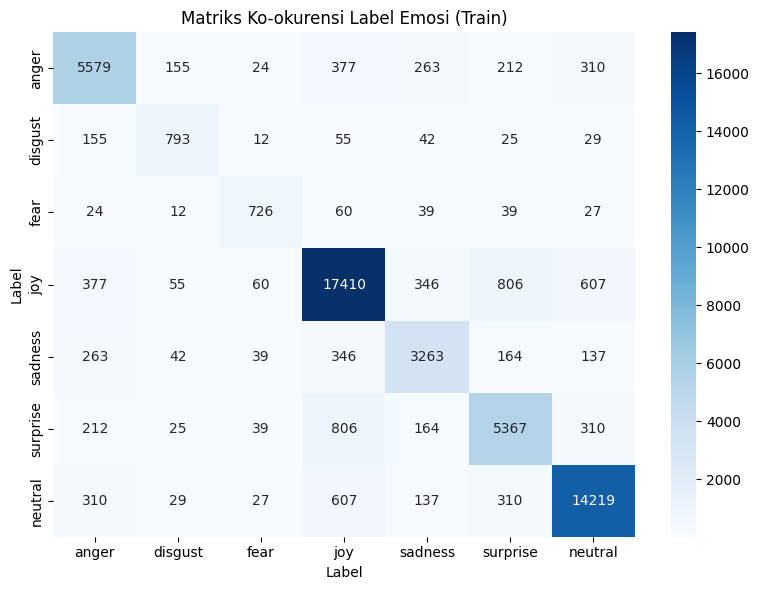

10 pasangan label yang paling sering muncul bersama:


,label_1,label_2,jumlah_bersama
0,joy,surprise,806
1,joy,neutral,607
2,anger,joy,377
3,joy,sadness,346
4,anger,neutral,310
5,surprise,neutral,310
6,anger,sadness,263
7,anger,surprise,212
8,sadness,surprise,164
9,anger,disgust,155


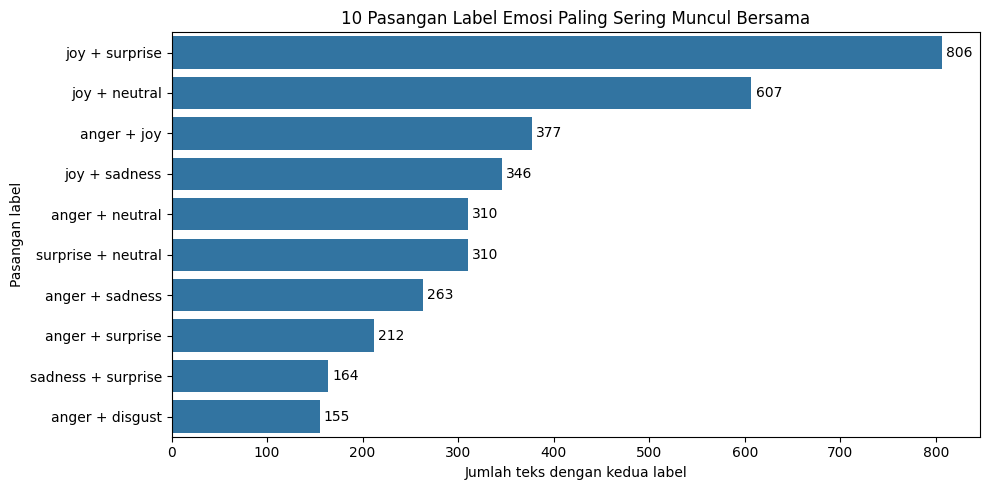

In [ ]:
# 4. Matriks ko-okurensi label
# Nilai sel menunjukkan berapa banyak teks yang memiliki kedua label sekaligus.
co_occurrence = train_df[LABELS].T.dot(train_df[LABELS])

plt.figure(figsize=(8, 6))
sns.heatmap(co_occurrence, annot=True, fmt="d", cmap="Blues")
plt.title("Matriks Ko-okurensi Label Emosi (Train)")
plt.xlabel("Label")
plt.ylabel("Label")
plt.tight_layout()
plt.show()

# Cari pasangan label berbeda yang paling sering muncul bersama
pair_counts = []
for label_a, label_b in combinations(LABELS, 2):
    count = int(((train_df[label_a] == 1) & (train_df[label_b] == 1)).sum())
    pair_counts.append((label_a, label_b, count))

pair_summary = pd.DataFrame(
    pair_counts, columns=["label_1", "label_2", "jumlah_bersama"]
).sort_values("jumlah_bersama", ascending=False).reset_index(drop=True)

print("10 pasangan label yang paling sering muncul bersama:")
display(pair_summary.head(10))

top_pairs = pair_summary.head(10).copy()
top_pairs["pasangan"] = top_pairs["label_1"] + " + " + top_pairs["label_2"]

plt.figure(figsize=(10, 5))
sns.barplot(data=top_pairs, x="jumlah_bersama", y="pasangan")
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.title("10 Pasangan Label Emosi Paling Sering Muncul Bersama")
plt.xlabel("Jumlah teks dengan kedua label")
plt.ylabel("Pasangan label")
plt.tight_layout()
plt.show()

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Statistik panjang teks (jumlah karakter):


,text_length_chars
count,43410.00
mean,68.40
std,36.72
min,2.00
50%,65.00
75%,96.00
90%,120.00
95%,131.00
99%,151.00
max,703.00


Statistik panjang teks (jumlah kata):


,text_length_words
count,43410.00
mean,12.84
std,6.70
min,1.00
50%,12.00
75%,18.00
90%,22.00
95%,24.00
99%,27.00
max,33.00


Statistik panjang teks (jumlah token DistilBERT):


,token_length
count,43410.00
mean,19.17
std,8.68
min,3.00
50%,19.00
75%,26.00
90%,31.00
95%,34.00
99%,38.00
max,316.00


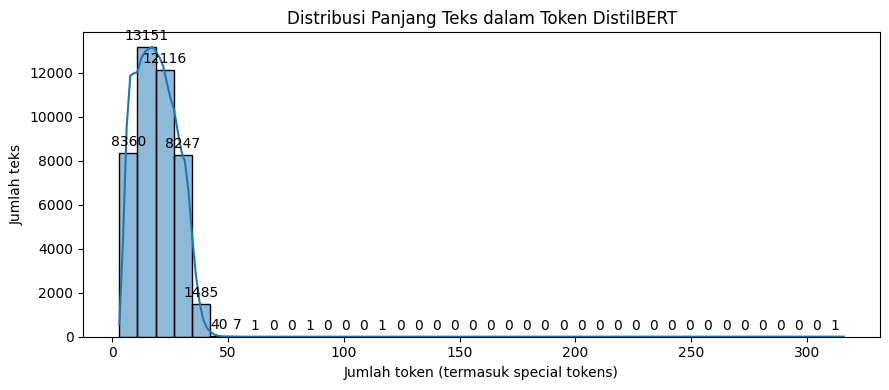

,max_length,teks_melebihi_batas,persentase_melebihi_batas_%
0,32,3012,6.94
1,64,3,0.01
2,128,1,0.00
3,256,1,0.00
4,512,0,0.00


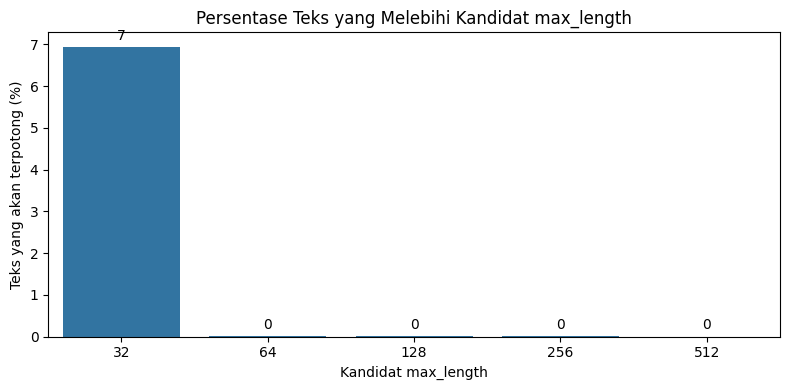

Persentil panjang token:
0.50    19.0
0.75    26.0
0.90    31.0
0.95    34.0
0.99    38.0
Name: token_length, dtype: float64

Catatan interpretasi:
- max_length lebih kecil menghemat memori dan waktu, tetapi lebih banyak teks dapat terpotong.
- max_length lebih besar mempertahankan lebih banyak teks, tetapi komputasi lebih berat.
- Tentukan max_length berdasarkan distribusi panjang token dan sumber daya komputasi; jangan memilih hanya dari satu grafik.


In [ ]:
# 5. Analisis panjang teks menggunakan tokenizer DistilBERT
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Hitung panjang token termasuk special tokens, tanpa truncation.
# EDA panjang teks dilakukan pada data train.
train_df["text_length_chars"] = train_df["text"].fillna("").astype(str).str.len()
train_df["text_length_words"] = (
    train_df["text"].fillna("").astype(str).str.split().str.len()
)

token_lengths = []
for text_value in train_df["text"].fillna("").astype(str):
    encoded = tokenizer(
        text_value,
        truncation=False,
        add_special_tokens=True
    )
    token_lengths.append(len(encoded["input_ids"]))

train_df["token_length"] = token_lengths

print("Statistik panjang teks (jumlah karakter):")
display(train_df["text_length_chars"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame().round(2))

print("Statistik panjang teks (jumlah kata):")
display(train_df["text_length_words"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame().round(2))

print("Statistik panjang teks (jumlah token DistilBERT):")
display(train_df["token_length"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99
    ]
).to_frame().round(2))

plt.figure(figsize=(9, 4))
sns.histplot(train_df["token_length"], bins=40, kde=True)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.title("Distribusi Panjang Teks dalam Token DistilBERT")
plt.xlabel("Jumlah token (termasuk special tokens)")
plt.ylabel("Jumlah teks")
plt.tight_layout()
plt.show()

# Perbandingan beberapa kandidat max_length.
# DistilBERT mendukung hingga 512 token; pilih berdasarkan persentase teks yang terpotong dan biaya komputasi.
candidate_lengths = [32, 64, 128, 256, 512]
length_rows = []
for max_len in candidate_lengths:
    n_over = int((train_df["token_length"] > max_len).sum())
    length_rows.append({
        "max_length": max_len,
        "teks_melebihi_batas": n_over,
        "persentase_melebihi_batas_%": n_over / len(train_df) * 100
    })

length_summary = pd.DataFrame(length_rows)
display(length_summary.round(2))

plt.figure(figsize=(8, 4))
sns.barplot(data=length_summary, x="max_length", y="persentase_melebihi_batas_%")
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.title("Persentase Teks yang Melebihi Kandidat max_length")
plt.xlabel("Kandidat max_length")
plt.ylabel("Teks yang akan terpotong (%)")
plt.tight_layout()
plt.show()

print("Persentil panjang token:")
print(train_df["token_length"].quantile([0.50, 0.75, 0.90, 0.95, 0.99]).round(2))

print("\nCatatan interpretasi:")
print("- max_length lebih kecil menghemat memori dan waktu, tetapi lebih banyak teks dapat terpotong.")
print("- max_length lebih besar mempertahankan lebih banyak teks, tetapi komputasi lebih berat.")
print("- Tentukan max_length berdasarkan distribusi panjang token dan sumber daya komputasi; jangan memilih hanya dari satu grafik.")

### **Sampling**

In [ ]:
def balance_single_multi(df, random_state=42):

    df = df.copy()

    single_label = df[df["num_labels"] == 1].copy()
    multi_label = df[df["num_labels"] >= 2].copy()

    print("\nSebelum sampling:")
    print("Single-label :", len(single_label))
    print("Multi-label  :", len(multi_label))

    n_sample = min(len(single_label), len(multi_label))

    single_label_sample = single_label.sample(n=n_sample,random_state=random_state)

    balanced_df = pd.concat(
        [
            single_label_sample,
            multi_label
        ],
        ignore_index=True
    )

    balanced_df = balanced_df.sample(frac=1, random_state=random_state).reset_index(drop=True)

    print("Sesudah sampling:")
    print(balanced_df["num_labels"].value_counts().sort_index())

    return balanced_df

In [ ]:
train_balanced = balance_single_multi(train_df)
val_balanced = balance_single_multi(val_df)

print("\nOriginal train :", len(train_df))
print("Balanced train :", len(train_balanced))

print("Original val   :", len(val_df))
print("Balanced val   :", len(val_balanced))


Sebelum sampling:
Single-label : 39555
Multi-label  : 3855
Sesudah sampling:
num_labels
1    3855
2    3763
3      92
Name: count, dtype: int64

Sebelum sampling:
Single-label : 4946
Multi-label  : 480
Sesudah sampling:
num_labels
1    480
2    468
3     12
Name: count, dtype: int64

Original train : 43410
Balanced train : 7710
Original val   : 5426
Balanced val   : 960


In [ ]:
print("TRAIN BALANCED")
print(train_balanced["num_labels"].value_counts().sort_index())

print("\nVALIDATION BALANCED")
print(val_balanced["num_labels"].value_counts().sort_index())

TRAIN BALANCED
num_labels
1    3855
2    3763
3      92
Name: count, dtype: int64

VALIDATION BALANCED
num_labels
1    480
2    468
3     12
Name: count, dtype: int64


# Transformer Model Selection
Model Transformer yang dipilih adalah DistilBERT (distilbert-base-uncased), yaitu model bahasa pre-trained yang lebih ringan dibandingkan BERT-base. DistilBERT dipilih karena dataset menggunakan teks berbahasa Inggris, mendukung fine-tuning untuk klasifikasi teks, serta memiliki kebutuhan komputasi yang relatif lebih rendah. Model akan dilengkapi dengan classification head berjumlah tujuh output untuk memprediksi tujuh kategori emosi secara independen.

# Tokenizer & Input Representation

In [ ]:
# Transformer Configuration

MODEL_NAME = "distilbert-base-uncased"
NUM_LABELS = len(LABELS)

# Nilai awal, evaluasi berdasarkan length_summary
MAX_LENGTH = 64

print("Model:", MODEL_NAME)
print("Number of labels:", NUM_LABELS)
print("Maximum sequence length:", MAX_LENGTH)

# Contoh data dari training set
sample_text = train_df.iloc[0]["text"]
sample_labels = train_df.iloc[0][LABELS].to_numpy(dtype=np.float32)

# Tokenisasi
encoded = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

print("\nOriginal text:")
print(sample_text)

print("\nTokenized text:")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"][0]))

print("\nInput IDs shape:", encoded["input_ids"].shape)
print("Attention mask shape:", encoded["attention_mask"].shape)

print("\nMulti-hot labels:")
print(dict(zip(LABELS, sample_labels.astype(int))))

print("\nLabel shape:", sample_labels.shape)

Model: distilbert-base-uncased
Number of labels: 7
Maximum sequence length: 64

Original text:
My favourite food is anything I didn't have to cook myself.

Tokenized text:
['[CLS]', 'my', 'favourite', 'food', 'is', 'anything', 'i', 'didn', "'", 't', 'have', 'to', 'cook', 'myself', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']

Input IDs shape: torch.Size([1, 64])
Attention mask shape: torch.Size([1, 64])

Multi-hot labels:
{'anger': np.int64(0), 'disgust': np.int64(0), 'fear': np.int64(0), 'joy': np.int64(0), 'sadness': np.int64(0), 'surprise': np.int64(0), 'neutral': np.int64(1)}

Label shape

# Model Architecture, Output Layer, Activation, & Loss

In [ ]:
# Model Architecture

from transformers import AutoModelForSequenceClassification
import torch

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification",
    id2label=ID2LABEL,
    label2id=LABEL2ID
).to(device)

# Loss untuk multi-label classification
loss_fn = torch.nn.BCEWithLogitsLoss()

print("Model:", model.config.model_type)
print("Number of labels:", model.config.num_labels)
print("Problem type:", model.config.problem_type)
print("\nClassification head:")
print(model.classifier)

print("\nLoss function:")
print(loss_fn)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: distilbert
Number of labels: 7
Problem type: multi_label_classification

Classification head:
Linear(in_features=768, out_features=7, bias=True)

Loss function:
BCEWithLogitsLoss()


# Forward Pass and Output Inspection

In [ ]:
model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=encoded["input_ids"].to(device),
        attention_mask=encoded["attention_mask"].to(device)
    )

# Output mentah model
logits = outputs.logits

# Konversi logits menjadi probabilitas
probabilities = torch.sigmoid(logits)

# Threshold awal untuk multi-label classification
THRESHOLD = 0.5
predictions = (probabilities >= THRESHOLD).int()

# Tampilkan hasil
result_df = pd.DataFrame({
    "Emotion": LABELS,
    "Probability": probabilities[0].cpu().numpy(),
    "Prediction": predictions[0].cpu().numpy(),
    "Ground Truth": sample_labels.astype(int)
})

print("Input shape:", encoded["input_ids"].shape)
print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)

print("\nForward Pass Results:")
display(result_df.round(4))

Input shape: torch.Size([1, 64])
Logits shape: torch.Size([1, 7])
Probabilities shape: torch.Size([1, 7])

Forward Pass Results:


,Emotion,Probability,Prediction,Ground Truth
0,anger,0.4880,0,0
1,disgust,0.4809,0,0
2,fear,0.5196,1,0
3,joy,0.5001,1,0
4,sadness,0.5113,1,0
5,surprise,0.4571,0,0
6,neutral,0.5258,1,1


# Hyperparameter Experimental Design

In [ ]:
experiment_plan = pd.DataFrame([
    {
        "Experiment": "E1 - Baseline",
        "Learning Rate": 2e-5,
        "Batch Size": 16,
        "Epochs": 3,
        "Max Length": 64
    },
    {
        "Experiment": "E2 - Learning Rate",
        "Learning Rate": 3e-5,
        "Batch Size": 16,
        "Epochs": 3,
        "Max Length": 64
    },
    {
        "Experiment": "E3 - Learning Rate",
        "Learning Rate": 5e-5,
        "Batch Size": 16,
        "Epochs": 3,
        "Max Length": 64
    },
    {
        "Experiment": "E4 - Batch Size",
        "Learning Rate": 2e-5,
        "Batch Size": 32,
        "Epochs": 3,
        "Max Length": 64
    },
    {
        "Experiment": "E5 - Epochs",
        "Learning Rate": 2e-5,
        "Batch Size": 16,
        "Epochs": 5,
        "Max Length": 64
    },
    {
        "Experiment": "E6 - Max Length",
        "Learning Rate": 2e-5,
        "Batch Size": 16,
        "Epochs": 3,
        "Max Length": 128
    }
])

display(experiment_plan)

,Experiment,Learning Rate,Batch Size,Epochs,Max Length
0,E1 - Baseline,0.00002,16,3,64
1,E2 - Learning Rate,0.00003,16,3,64
2,E3 - Learning Rate,0.00005,16,3,64
3,E4 - Batch Size,0.00002,32,3,64
4,E5 - Epochs,0.00002,16,5,64
5,E6 - Max Length,0.00002,16,3,128


# Evaluation Metrics & Threshold Selection

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, hamming_loss

threshold_candidates = [0.3, 0.4, 0.5, 0.6, 0.7]

evaluation_plan = pd.DataFrame({
    "Threshold": threshold_candidates,
    "Micro-F1": [np.nan] * len(threshold_candidates),
    "Macro-F1": [np.nan] * len(threshold_candidates),
    "Hamming Loss": [np.nan] * len(threshold_candidates)
})

print("Planned evaluation metrics:")
print("- Micro-F1")
print("- Macro-F1")
print("- Precision")
print("- Recall")
print("- Hamming Loss")

print("\nThreshold candidates:")
display(evaluation_plan)

print("Note: Evaluation scores will be calculated after fine-tuning.")

Planned evaluation metrics:
- Micro-F1
- Macro-F1
- Precision
- Recall
- Hamming Loss

Threshold candidates:


,Threshold,Micro-F1,Macro-F1,Hamming Loss
0,0.3,NaN,NaN,NaN
1,0.4,NaN,NaN,NaN
2,0.5,NaN,NaN,NaN
3,0.6,NaN,NaN,NaN
4,0.7,NaN,NaN,NaN


Note: Evaluation scores will be calculated after fine-tuning.
